# ДЗ 1. Собственная decoder-модель на PyTorch

Вам предстоит разработать небольшую языковую модель для продолжения русскоязычного текста.

Нужно пройти весь цикл: собрать decoder, проверить его, обучить, заменить три компонента и сравнить качество.

Также, необходимо провести эксперименты и составить анализ для ответа на исследовательский вопрос: как последовательная замена LayerNorm на RMSNorm, ReLU FFN на SwiGLU и синусоидальных позиций на RoPE меняет поведение модели?

Вход модели — индексы токенов `(B, T)`, выход — логиты `(B, T, V)`.
Это decoder-only модель: encoder и cross-attention здесь не нужны.

Данные, BPE, батчи, оценка и обвязка экспериментов уже написаны. Вам необходимо заполнить пробелы и обучить модели.

Для сдачи нужны предоставить: ноутбук с выводами всех четырёх прогонов, графики и таблица, ответы на вопросы.

**Для начала работы, скопируйте ноутбук к себе на диск и продолжайте работать в Colab на своем Google Drive.**

Для обучения моделей, можете использовать GPU: «Среда выполнения → Сменить среду выполнения → GPU» (когда написали рабочий код).

Корпус текста скачается автоматически.

Сначала включите `QUICK_RUN = True` в ячейке параметров. После успешных проверок переключите его в `False` и перезапустите среду с выполнением всех ячеек на GPU. Короткий режим проверяет работоспособность, но не заменяет четыре основных прогона.


In [1]:
import csv
import json
import math
import re
import shutil
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)

print('PyTorch:', torch.__version__, '| device:', DEVICE)


PyTorch: 2.14.1+cu130 | device: cuda


## 1. Данные и цели (1 балл)

Дан корпус книги «Евгений Онегин» с вебинаров.

Корпус разделяем на train и val выборки (9 к 1). BPE обучается только на train.

> Это небольшой корпус: мы проверяем архитектуру и инженерный цикл, а не обучаем
универсальную LLM. Словарь 512 намеренно небольшой, чтобы не тратить основную
часть параметров на эмбеддинги и выходной слой.

Прочитайте готовую подготовку данных. Убедитесь, что `y[b, t]` — токен **после**
`x[b, t]`, а не тот же токен. Иначе получится задача копирования.


In [2]:
DATA_URL = 'https://raw.githubusercontent.com/neychev/small_DL_repo/master/datasets/onegin.txt'

data_path = Path('onegin.txt')
if not data_path.exists():
    with urllib.request.urlopen(DATA_URL) as response:
        data_path.write_bytes(response.read())

In [3]:
TEXT = data_path.read_text(encoding='utf-8').replace('\t', '')
split = int(0.9 * len(TEXT))
train_text, val_text = TEXT[:split], TEXT[split:]

In [4]:
print(f'Символов: train={len(train_text):,}, validation={len(val_text):,}')

Символов: train=127,699, validation=14,189


In [5]:
# Токенайзер с вебинара
PAT = re.compile(r" ?\w+| ?[^\w\s]+|\s+")


def get_stats(words):
    stats = Counter()
    for w, count in words.items():
        for pair in zip(w, w[1:]):
            stats[pair] += count
    return stats


def merge(ids, pair, new_id):
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
            out.append(new_id)
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out


def train_bpe(text, vocab_size):
    words = Counter(tuple(w.encode("utf-8")) for w in PAT.findall(text))
    merges, vocab = {}, {i: bytes([i]) for i in range(256)}
    for new_id in range(256, vocab_size):
        stats = get_stats(words)
        pair = max(stats, key=stats.get)
        merges[pair] = new_id
        vocab[new_id] = vocab[pair[0]] + vocab[pair[1]]
        words = {tuple(merge(list(w), pair, new_id)): c for w, c in words.items()}
    return merges, vocab


def encode(text, merges):
    ids = []
    for chunk in PAT.findall(text):
        chunk_ids = list(chunk.encode("utf-8"))
        while len(chunk_ids) >= 2:
            pair = min(zip(chunk_ids, chunk_ids[1:]), key=lambda p: merges.get(p, float("inf")))
            if pair not in merges:
                break
            chunk_ids = merge(chunk_ids, pair, merges[pair])
        ids.extend(chunk_ids)
    return ids


def decode(ids, vocab):
    return b"".join(vocab[int(i)] for i in ids).decode("utf-8", errors="replace")


In [6]:
merges, vocab = train_bpe(train_text, 512)
V = len(vocab)

train_ids = torch.tensor(encode(train_text, merges))
val_ids = torch.tensor(encode(val_text, merges))

In [7]:
print(f'Словарь={V}, train={len(train_ids):,} токенов, validation={len(val_ids):,}')
print(f'Символов на токен в train: {len(train_text) / len(train_ids):.2f}')

Словарь=512, train=77,219 токенов, validation=8,520
Символов на токен в train: 1.65


In [8]:
def get_batch(ids, batch_size, context, generator):
    """Случайные окна длины context и те же окна, сдвинутые на один токен вправо."""
    starts = torch.randint(len(ids) - context, (batch_size,), generator=generator)
    x = torch.stack([ids[s:s + context] for s in starts])
    y = torch.stack([ids[s + 1:s + context + 1] for s in starts])
    return x.to(DEVICE), y.to(DEVICE)


toy_x, toy_y = get_batch(torch.arange(20), 2, 8, torch.Generator().manual_seed(0))
print('x:', toy_x.tolist(), '\ny:', toy_y.tolist())


x: [[8, 9, 10, 11, 12, 13, 14, 15], [3, 4, 5, 6, 7, 8, 9, 10]] 
y: [[9, 10, 11, 12, 13, 14, 15, 16], [4, 5, 6, 7, 8, 9, 10, 11]]


**Вопрос 1.**

Зачем делить текст до
обучения BPE и почему при обучении decoder нужны и сдвиг целей, и causal mask.
После исправлений снова выполните проверки этой части.

**Ответ:**

Текст делится на train/val до обучения BPE, чтобы словарь не подсматривал validation. Иначе правила слияния пар байт учитывали бы частоты в val, а это утечка и validation перестаёт быть независимой оценкой, так как токенизатор подстроен под неё. Модель на val окажется в более выгодных условиях, чем на реально новых данных, и метрика будет завышена.
При обучении decoder нужны и сдвиг целей, и causal mask, потому что они закрывают разные дыры: сдвиг задаёт правильную цель (предсказать следующий токен), а маска запрещает позиции t видеть будущие входные токены, через которые можно подсмотреть цель (например, цель для позиции 0 присутствует во входе на позиции 1).  Только вместе они дают честную задачу "предсказать следующий токен, видя только прошлое".


### Параметры всех четырёх прогонов

Если Colab ограничивает ресурсы, разрешается уменьшить размер модели, batch size
или число шагов **одинаково для всех четырёх конфигураций**. Укажите изменение
и причину в отчёте. Порог по perplexity не задан; корректность нельзя заменить
долгим обучением. Максимум баллов доступен и с обоснованным уменьшением бюджета,
если выполнены четыре сопоставимых прогона и анализ.


In [9]:
QUICK_RUN = False

BASE_CONFIG = dict(
    vocab_size=V, d_model=192, n_layers=4, n_heads=6, max_seq_len=128,
    dropout=0.1, norm_type='layernorm', ffn_type='relu', pos_type='sinusoidal',
)

BATCH_SIZE = 32
TRAIN_STEPS = 1000
EVAL_EVERY = 100
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1

if QUICK_RUN:
    BASE_CONFIG.update(d_model=48, n_layers=2, n_heads=3, max_seq_len=32)
    BATCH_SIZE, TRAIN_STEPS, EVAL_EVERY = 4, 20, 10

ARTIFACTS = Path('artifacts_quick' if QUICK_RUN else 'artifacts')
ARTIFACTS.mkdir(exist_ok=True)

In [10]:
print('Режим:', 'ОТЛАДКА' if QUICK_RUN else 'основной', '| шагов:', TRAIN_STEPS)

Режим: основной | шагов: 1000


## 2. Causal attention и decoder (7 баллов)

Базовая схема:

`tokens → Embedding + sinusoidal positions → N × DecoderBlock → LayerNorm → Linear → logits`.

Внутри блока:

$$u=x+\operatorname{Dropout}(\operatorname{Attention}(\operatorname{Norm}_1(x))),$$
$$z=u+\operatorname{Dropout}(\operatorname{FFN}(\operatorname{Norm}_2(u))).$$

Мы используем **Pre-LN с финальной нормализацией** во всех вариантах, чтобы
расположение нормализации не менялось одновременно с её типом. Это учебный
baseline, а не точная копия трансформера 2017 года. Cross-attention отсутствует.
Смещения линейных слоёв отключены; входные и выходные эмбеддинги раздельные.

### 2.1. Внимание (4 балла)

Реализуйте `forward`. Разделите Q/K/V на головы `(B, H, T, D)`, где `D=C/H`.
Вычислите `Q @ K.transpose(-2, -1) / sqrt(D)`. Маска должна запрещать только
`j > i`: токену разрешено смотреть на себя. Примените softmax по ключам,
dropout весов внимания, умножение на V, объединение голов и проекцию.

RoPE понадобится в части 4: если `self.pos_type == 'rope'`, вызовите
`apply_rope` для Q и K после разделения на головы.


In [11]:
def sinusoidal_positions(length, width):
    positions = torch.arange(length, dtype=torch.float32)[:, None]
    frequencies = torch.exp(torch.arange(0, width, 2) * (-math.log(10000.0) / width))
    table = torch.zeros(length, width)
    table[:, 0::2] = torch.sin(positions * frequencies)
    table[:, 1::2] = torch.cos(positions * frequencies)
    return table


In [12]:
class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.n_heads = config['n_heads']
        self.head_dim = config['d_model'] // self.n_heads
        self.pos_type = config['pos_type']

        c = config['d_model']

        self.q_proj = nn.Linear(c, c, bias=False)
        self.k_proj = nn.Linear(c, c, bias=False)
        self.v_proj = nn.Linear(c, c, bias=False)
        self.out_proj = nn.Linear(c, c, bias=False)
        self.attn_dropout = nn.Dropout(config['dropout'])

    def forward(self, x):
        """x: (B, T, C), результат: (B, T, C)."""
        B, T, C = x.shape
        H, D = self.n_heads, self.head_dim

        q = self.q_proj(x).view(B, T, H, D).transpose(1, 2)
        k = self.k_proj(x).view(B, T, H, D).transpose(1, 2)
        v = self.v_proj(x).view(B, T, H, D).transpose(1, 2)

        if self.pos_type == 'rope':
            q = apply_rope(q)
            k = apply_rope(k)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(D)

        #causal mask
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1)
        att = att.masked_fill(mask, float('-inf'))
        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)
        y = att @ v  # (B, H, T, D)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(y)

        # TODO 1: Q/K/V, головы, RoPE при необходимости, causal mask, softmax, выход.



In [13]:
def check_attention_only():
    torch.manual_seed(123)
    config = dict(BASE_CONFIG, d_model=48, n_heads=3, n_layers=2, max_seq_len=12, dropout=0.0)

    attention = CausalSelfAttention(config).to(DEVICE)
    attention.eval()  # dropout=0 и так, но eval() фиксирует поведение

    x = torch.randn(2, 7, 48, device=DEVICE)
    q, k, v = [
        p(x).reshape(2, 7, 3, 16).transpose(1, 2)
        for p in (attention.q_proj, attention.k_proj, attention.v_proj)
    ]
    expected = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(2, 7, 48)
    torch.testing.assert_close(attention(x), attention.out_proj(expected), atol=2e-5, rtol=2e-5)

    # причинность: изменение правой части входа не меняет левые выходы
    x2 = x.clone()
    x2[:, 4:] = torch.randn_like(x2[:, 4:])
    torch.testing.assert_close(attention(x)[:, :4], attention(x2)[:, :4], atol=2e-5, rtol=2e-5)

    print('OK: attention совпадает с SDPA, причинность (T=7) проверена.')

check_attention_only()

OK: attention совпадает с SDPA, причинность (T=7) проверена.


### 2.2. Сборка модели (3 балла)

В `DecoderBlock.forward` используйте **два последовательных** residual-сложения:
FFN должен получать результат обновления attention. В `DecoderLM.forward`
добавляйте синусоидальные позиции только в режиме `sinusoidal`, затем выполните
блоки, финальную нормализацию и `lm_head`. Softmax перед cross-entropy не нужен.

Готовые конструкторы ссылаются на RMSNorm и SwiGLU из части 4. В текущем режиме
эти классы ещё не используются: сначала можно отладить LayerNorm + ReLU.


In [14]:
class DecoderBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        width = config['d_model']

        norm = nn.LayerNorm if config['norm_type'] == 'layernorm' else RMSNorm
        self.norm1, self.norm2 = norm(width), norm(width)

        self.attention = CausalSelfAttention(config)
        self.ffn = (
            nn.Sequential(
                nn.Linear(width, 4 * width, bias=False),
                nn.ReLU(),
                nn.Linear(4 * width, width, bias=False)
            )
            if config['ffn_type'] == 'relu' else SwiGLU(width)
        )
        self.dropout = nn.Dropout(config['dropout'])

    def forward(self, x):
        u = x + self.dropout(self.attention(self.norm1(x)))
        z = u + self.dropout(self.ffn(self.norm2(u)))
        return z
        # TODO 2: Pre-LN, attention, FFN и два residual-сложения.


In [15]:
class DecoderLM(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config

        width = config['d_model']

        self.embedding = nn.Embedding(config['vocab_size'], width)
        self.register_buffer('positions', sinusoidal_positions(config['max_seq_len'], width))

        self.dropout = nn.Dropout(config['dropout'])

        self.blocks = nn.ModuleList(
            [DecoderBlock(config) for _ in range(config['n_layers'])]
        )

        norm = nn.LayerNorm if config['norm_type'] == 'layernorm' else RMSNorm
        self.final_norm = norm(width)

        self.lm_head = nn.Linear(width, config['vocab_size'], bias=False)

    def forward(self, input_ids):
        """input_ids: LongTensor (B, T), T <= max_seq_len; возвращает логиты (B, T, V)."""
        assert input_ids.shape[1] <= self.config['max_seq_len'], 'Обрежьте вход до max_seq_len.'
        B, T = input_ids.shape
        x = self.embedding(input_ids)
        if self.config['pos_type'] == 'sinusoidal':
            x = x + self.positions[:T].unsqueeze(0)
        x = self.dropout(x)
        for block in self.blocks:
            x = block(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)
        return logits
        # TODO 3: эмбеддинги, позиции только для sinusoidal, блоки, нормализация и логиты.



In [16]:
def check_baseline():
    torch.manual_seed(123)
    config = dict(BASE_CONFIG, d_model=48, n_heads=3, n_layers=2, max_seq_len=12, dropout=0.0)

    attention = CausalSelfAttention(config).to(DEVICE)
    x = torch.randn(2, 7, 48, device=DEVICE)
    q, k, v = [
        p(x).reshape(2, 7, 3, 16).transpose(1, 2)
        for p in (attention.q_proj, attention.k_proj, attention.v_proj)
    ]
    expected = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(2, 7, 48)
    torch.testing.assert_close(attention(x), attention.out_proj(expected), atol=2e-5, rtol=2e-5)

    model = DecoderLM(config).to(DEVICE)
    ids = torch.randint(V, (2, 12), device=DEVICE)
    altered = ids.clone()
    altered[:, 6:] = (altered[:, 6:] + 1) % V
    logits = model(ids)
    assert logits.shape == (2, 12, V) and torch.isfinite(logits).all()

    torch.testing.assert_close(logits[:, :6], model(altered)[:, :6], atol=2e-5, rtol=2e-5)
    torch.testing.assert_close(logits[:, :6], model(ids[:, :6]), atol=2e-5, rtol=2e-5)
    print('База: attention совпадает с SDPA, формы и причинность проверены.')

check_baseline()

База: attention совпадает с SDPA, формы и причинность проверены.


**Вопрос 2.**

окажите формы Q/K/V и маски для `B=2, T=7, H=3, D=16`.
Почему маска накладывается до softmax? Чем отличаются `model.eval()` и `no_grad()`?
Если тест упал, сначала проверьте ось softmax и направление маски.

**Ответ:**

Формы (B=2, T=7, H=3, D=16, C=48): вход x: (2, 7, 48); Q, K, V после view(B,T,H,D).transpose(1,2): (2, 3, 7, 16); att = Q @ K^T / √D: (2, 3, 7, 7); маска triu(diagonal=1): (7, 7), broadcast до (2, 3, 7, 7); att @ V: (2, 3, 7, 16) → view(B,T,C): (2, 7, 48)

Маска ставится до softmax, чтобы запрещённые позиции сразу получили нулевой вес: экспонента от минус бесконечности равна нулю, поэтому в сумме по строке участвуют только разрешённые позиции, и веса по-прежнему складываются в единицу. Если же обнулять веса после softmax, знаменатель уже посчитан по всем позициям, включая запрещённые, и сумма по строке станет меньше единицы. Т.е.часть «массы» потеряется, и это будет уже не усреднение, а масштабирование. Также градиент через запрещённые позиции всё равно течёт (они участвовали в знаменателе), то есть блокировка неполная.

В общем случае eval() переключает поведение слоёв, зависящих от режима (dropout, BatchNorm); в нашей модели это касается только dropout, потому что LayerNorm/RMSNorm от режима не зависят. Но граф вычислений при этом всё равно строится и память под него тратится. no_grad() наоборот: граф не строится, память экономится, но на dropout (и на BatchNorm, если бы он был) никак не влияет, если модель в режиме обучения, dropout продолжит шуметь. Для предсказаний нужны оба: eval(), чтобы слои вели себя предсказуемо, и no_grad(), чтобы не тратить память на ненужный граф. А evaluate в конце возвращает модели прежний режим через train(was_training), иначе после оценки она осталась бы в eval и следующие шаги обучения шли бы без dropout.

## 3. Обучение (3 балла)

Реализуйте `train_step`: режим обучения, `zero_grad`, logits, cross-entropy,
`backward`, clipping нормы градиентов до 1, шаг оптимизатора. Верните число loss.

Проверьте конечность loss (`clip_grad_norm_` используйте `error_if_nonfinite=True`).


In [17]:
def train_step(model, optimizer, x, y):
    """Один шаг обновления весов; вернуть loss как float."""
    model.train()
    logits = model(x)
    loss = F.cross_entropy(logits.flatten(0, 1), y.flatten())
    if not torch.isfinite(loss):
        raise FloatingPointError(f'non-finite loss: {loss.item()}')
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
    optimizer.step()
    return float(loss.item())

    # TODO 4: logits, CE, zero_grad/backward/clipping/step, контроль конечности.



In [18]:
@torch.no_grad()
def evaluate(model, ids, batch_size=32):
    """Средний NLL на целевой токен: непересекающиеся окна max_seq_len плюс неполный хвост."""
    was_training = model.training
    model.eval()
    context = model.config['max_seq_len']
    x, y = ids[:-1], ids[1:]
    full = len(x) // context * context
    chunks = list(zip(x[:full].reshape(-1, context).split(batch_size), y[:full].reshape(-1, context).split(batch_size)))
    if full < len(x):
        chunks.append((x[full:][None], y[full:][None]))
    total = sum(F.cross_entropy(model(xb.to(DEVICE)).flatten(0, 1), yb.to(DEVICE).flatten(), reduction='sum').item()
                for xb, yb in chunks)
    model.train(was_training)
    return total / len(x)


def check_training():
    torch.manual_seed(13)
    config = dict(BASE_CONFIG, vocab_size=32, d_model=48, n_heads=3, n_layers=1, max_seq_len=12, dropout=0.0)
    model = DecoderLM(config).to(DEVICE)
    x = torch.randint(32, (4, 12), device=DEVICE)
    y = torch.randint(32, (4, 12), device=DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=0)
    losses = [train_step(model, optimizer, x, y) for _ in range(80)]
    assert losses[-1] < 0.25 * losses[0], losses[::20]
    assert all(torch.isfinite(p.grad).all() for p in model.parameters())
    print(f'Обучение: loss одного батча {losses[0]:.3f} → {losses[-1]:.3f}.')

check_training()

Обучение: loss одного батча 3.579 → 0.000.


## 4. RMSNorm, SwiGLU, RoPE (4 балла)

### 4.1. RMSNorm (1 балл)

$$\operatorname{RMSNorm}(x)=\gamma\odot x\left(\frac{1}{d}\sum_i x_i^2+\varepsilon\right)^{-1/2}.$$

Нормируйте последнюю ось, используйте `self.eps` и обучаемый `self.weight`.
Среднее не вычитается, параметра beta нет. Замена включает финальную нормализацию.

### 4.2. SwiGLU (1 балл)

$$\operatorname{SwiGLU}(x)=W_{down}\big(\operatorname{SiLU}(W_{gate}x)\odot W_{up}x\big).$$

У ReLU FFN две матрицы и ширина `4d`, у SwiGLU — три и ширина `8d/3`.
При `d=192` это 768 и 512 соответственно. Веса FFN сопоставимы по числу параметров.
В коротком режиме используем `d=48`, также кратное 3.

### 4.3. RoPE (2 балла)

На входе `(B, H, T, D)`. Для пары координат `(2i, 2i+1)` и позиции `t`:

$$\theta_i=10000^{-2i/D},\quad a=t\theta_i,$$
$$x'_{2i}=x_{2i}\cos a-x_{2i+1}\sin a,\quad
x'_{2i+1}=x_{2i}\sin a+x_{2i+1}\cos a.$$

Реализуйте поворот соседних пар. Учитывайте `offset` в тестах;
обычное обучение и генерация вызывают функцию с `offset=0`.
Частоты и позиции создавайте на том же устройстве, что вход.
RoPE применяется только к **Q и K**, не V. Синусоиды ко входу при RoPE не добавляются.


In [19]:
class RMSNorm(nn.Module):
    def __init__(self, width, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(width))
        self.eps = eps

    def forward(self, x):
        rms = x.pow(2).mean(dim=-1, keepdim=True)
        x_norm = x * torch.rsqrt(rms + self.eps)
        return x_norm * self.weight
        # TODO 5: RMS по последней оси, epsilon и обучаемый масштаб.


In [20]:
class SwiGLU(nn.Module):
    def __init__(self, width):
        super().__init__()

        hidden = 8 * width // 3
        self.gate = nn.Linear(width, hidden, bias=False)
        self.up = nn.Linear(width, hidden, bias=False)
        self.down = nn.Linear(hidden, width, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))

        # TODO 6: две ветви, SiLU, поэлементное произведение и проекция вниз.


In [21]:
def apply_rope(x, offset=0):
    """Поворот соседних пар: (B, H, T, D) → (B, H, T, D); позиция токена t равна offset + t."""
    B, H, T, D = x.shape
    assert D % 2 == 0, 'RoPE требует чётной головной размерности'
    half = D // 2
    theta = torch.exp(-math.log(10000.0) * torch.arange(half, device=x.device, dtype=x.dtype) * 2.0 / D)
    positions = torch.arange(offset, offset + T, device=x.device, dtype=x.dtype)
    angles = positions[:, None] * theta[None, :]

    cos = angles.cos()[None, None, :, :]
    sin = angles.sin()[None, None, :, :]

    x1 = x[..., 0::2]
    x2 = x[..., 1::2]

    rot1 = x1 * cos - x2 * sin
    rot2 = x1 * sin + x2 * cos

    out = torch.empty_like(x)
    out[..., 0::2] = rot1
    out[..., 1::2] = rot2
    return out

    # TODO 7: частоты, позиции с offset, cos/sin и поворот соседних пар.


In [22]:
def check_modern_components():
    torch.manual_seed(7)

    x = torch.randn(2, 3, 48, device=DEVICE)
    norm = RMSNorm(48).to(DEVICE)
    with torch.no_grad():
        norm.weight.copy_(torch.linspace(0.5, 1.5, 48, device=DEVICE))
    torch.testing.assert_close(norm(x), x / torch.sqrt(x.square().mean(-1, keepdim=True) + norm.eps) * norm.weight)
    assert torch.isfinite(norm(torch.zeros_like(x))).all()

    ffn = SwiGLU(48).to(DEVICE)
    torch.testing.assert_close(ffn(x), ffn.down(F.silu(ffn.gate(x)) * ffn.up(x)))
    assert sum(p.numel() for p in ffn.parameters()) == 2 * 48 * (4 * 48)

    q, k = torch.randn(2, 3, 9, 16, device=DEVICE), torch.randn(2, 3, 9, 16, device=DEVICE)
    torch.testing.assert_close(apply_rope(q).square().sum(-1), q.square().sum(-1), atol=1e-5, rtol=1e-5)
    torch.testing.assert_close(apply_rope(q)[..., 0, :], q[..., 0, :])
    dots = (apply_rope(q, 3) * apply_rope(k, 7)).sum(-1)
    shifted_dots = (apply_rope(q, 8) * apply_rope(k, 12)).sum(-1)
    torch.testing.assert_close(dots, shifted_dots, atol=2e-5, rtol=2e-5)
    quad = torch.tensor([[[[1.0, 0.0, 1.0, 0.0]]]], device=DEVICE)
    expected = torch.tensor([[[[math.cos(1), math.sin(1), math.cos(0.01), math.sin(0.01)]]]], device=DEVICE)
    torch.testing.assert_close(apply_rope(quad, 1), expected)

    config = dict(
        BASE_CONFIG,
        d_model=48,
        n_heads=3,
        n_layers=1,
        max_seq_len=12,
        dropout=0.0,
        norm_type='rmsnorm',
        ffn_type='swiglu',
        pos_type='rope',
    )
    model = DecoderLM(config).to(DEVICE)
    ids = torch.randint(V, (2, 12), device=DEVICE)
    swapped = ids.clone()
    swapped[:, [0, 1]] = ids[:, [1, 0]]
    logits = model(ids)

    # Один слой без позиций не различает порядок префикса: разница появляется только с RoPE
    assert not torch.allclose(logits[:, -1], model(swapped)[:, -1], atol=1e-4), 'RoPE не подключена к Q/K.'

    model.positions.zero_()
    torch.testing.assert_close(model(ids), logits, msg='При RoPE синусоиды не добавляются.')

    F.cross_entropy(logits.flatten(0, 1), ids.flatten()).backward()
    assert all(torch.isfinite(p.grad).all() for p in model.parameters())

    print('RMSNorm, SwiGLU, RoPE, её подключение и градиенты современной модели проверены.')

check_modern_components()


RMSNorm, SwiGLU, RoPE, её подключение и градиенты современной модели проверены.


**Вопрос3.** Перед обучением предскажите эффект каждой замены на число
параметров и на validation loss. Какие ожидания следуют из формул, а какие требуют
эксперимента? Почему отсутствие улучшения не доказывает бесполезность компонента?

**Ответ:**

Замена **LayerNorm на RMSNorm.** LayerNorm хранит два вектора на слой, RMSNorm только γ. Экономия d параметров на каждую норму; у нас нормы стоят в каждом блоке (norm1, norm2) и в финале. RMSNorm даёт 9·192 = 1728 параметров, LayerNorm — 2·9·192 = 3456, экономия 1728 параметров. При общем числе параметров модели около ~2M это не большая разница.
На validation loss это влияние небольшое, т.к изменения в параметрах и то, только в нормах, которые сами по себе не несут знания, не дадут эффекта, возможно только в доли процентов, что на таком масштабе может быть меньше, чем разница в seed.  А знак предсказать нельзя: RMSNorm не центрирует, поэтому зависит от того, насколько среднее активаций близко к нулю. Но это свойство данных и инициализации, а не формулы. Т.е. требует эксперимента. Данная замена нужна не для улучшения качесвта модели как таковой, а для устойчивость и увеличения скорости сходимости обучения на больших больших данных и длинных прогонах, которые в нашей задаче не представлены.

Замена **ReLU FFN на SwiGLU.** У ReLU FFN две матрицы ширины 4d, у SwiGLU три матрицы ширины 8d/3. Число параметров совпадает по построению (8d² в обоих случаях). Ожидаем лучший validation loss у SwiGLU. У ReLU всё отрицательное обнуляется и часть сигнала теряется, а у SwiGLU одна ветвь мягко «приглушает» сигнал (SiLU), а вторая решает, насколько его пропустить, и они перемножаются. Получается более гибкая нелинейность при том же числе параметров. Но нужно проверять экспериментом, подтвердится ли это на нашем корпусе. Корпус маленький (77k токенов), обучение короткое (1000 шагов), поэтому более выразительный блок может не успеть раскрыться: ему нужно больше данных и шагов.

Замена **Синусоиды на RoPE.** Обе схемы не добавляют параметров (синусоиды — буфер, RoPE вообще без параметров), число параметров не меняется. Ключевое отличие: синусоиды задают абсолютную позицию и для относительности нужно обучение, а RoPE включает относительность в архитектуру. Относительность особенно полезна, когда модель встречает последовательности длиннее, чем видела при обучении. Но в нашей задаче это преимущество негде проявить.  У нас max_seq_len = 128, и модель обучается на окнах не длиннее 128, и генерирует тоже в пределах 128. То есть длина контекста никогда не выходит за то, что модель видела, а именно там RoPE и должен был бы выиграть. Т.е. ожидать, что RoPE обгонит по validation loss из формулы нельзя и нужен эксперимент. Но даже при неизменных результатах нельзя утверждать, что RoPE хуже, просто на нашей задаче его преимущество не проявляется.

Из формул следует только число параметров (и то с оговоркой, разница в нормах ~0.09%). Знак и величина эффекта на validation loss из формул не выводятся: у RMSNorm зависит от распределения активаций, у SwiGLU от того, успеет ли более гибкая нелинейность раскрыться на малом корпусе, у RoPE от того, выходит ли контекст за обученную длину (у нас нет). Поэтому все три эффекта нужно проверять прогоном. Наш прогон: один seed, маленький корпус (77k токенов), короткое обучение (1000 шагов) и одна метрика (validation loss), а компоненты ценятся ещё за устойчивость, скорость сходимости и поведение на длинном контексте и ничего из этого мы не измеряем.


## 5. Генерация, эксперименты и передача модели (5 баллов)

**Опора:** декодирование из вебинаров; уроки 2 и 5 модуля 3.

### 5.1. Генерация и сохранение (2 балла)

Реализуйте `generate`: сохраняйте весь префикс в результате, но на каждом шаге
передавайте модели только последние `max_seq_len` токенов. Берите логиты последней
позиции. При `temperature=0` используйте argmax, иначе softmax с температурой
и `torch.multinomial`. Дописывайте один токен и повторяйте.

Декоратор отключает граф, `eval()` уже вызван. Позиции каждого переданного окна
начинаются с нуля.

Функции сохранения/загрузки готовы, но сдаваемая модель должна проходить проверку
совпадения логитов после загрузки. В checkpoint есть веса, конфигурация, BPE
и шаг выбора модели. Продолжение обучения из checkpoint не требуется.


In [23]:
@torch.no_grad()
def generate(model, input_ids, max_new_tokens=80, temperature=1.0):
    """Дописывает max_new_tokens токенов к префиксу (B, T); temperature=0 — greedy."""
    model.eval()
    max_len = model.config['max_seq_len']
    out = input_ids

    for _ in range(max_new_tokens):
        #На каждом шаге в модель идёт только последнее окно max_seq_len токенов
        window = out[:, -max_len:]
        logits = model(window)
        last = logits[:, -1, :]
        if temperature == 0:
            next_token = last.argmax(dim=-1, keepdim=True)
        else:
            probs = F.softmax(last / temperature, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
        out = torch.cat([out, next_token], dim=1)

    return out
    # TODO 8: окно контекста, последние логиты, greedy/sampling, дописывание токена.


In [24]:
def save_checkpoint(path, model, merges, step, val_loss):
    torch.save(dict(model_state=model.state_dict(), config=model.config, step=step, val_loss=val_loss,
                    merges=[[a, b, token] for (a, b), token in merges.items()]), path)


def load_checkpoint(path):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=True)

    restored_merges = {(a, b): token for a, b, token in checkpoint['merges']}
    restored_vocab = {i: bytes([i]) for i in range(256)}
    for (a, b), token in restored_merges.items():
        restored_vocab[token] = restored_vocab[a] + restored_vocab[b]

    model = DecoderLM(checkpoint['config']).to(DEVICE)
    model.load_state_dict(checkpoint['model_state'])
    model.eval()

    return model, restored_merges, restored_vocab, checkpoint


def check_generation_and_checkpoint():
    config = dict(
        BASE_CONFIG,
        d_model=48,
        n_heads=3,
        n_layers=1,
        max_seq_len=8,
        norm_type='rmsnorm',
        ffn_type='swiglu',
        pos_type='rope',
    )

    model = DecoderLM(config).to(DEVICE)
    ids = torch.tensor([encode('Мой дядя', merges)], device=DEVICE)
    greedy = generate(model, ids, 12, temperature=0)
    assert greedy.shape == (1, ids.shape[1] + 12) and torch.equal(greedy[:, :ids.shape[1]], ids)
    assert torch.equal(greedy, generate(model, ids, 12, temperature=0))

    sampled = generate(model, ids, 3, temperature=0.8)
    assert sampled.shape == (1, ids.shape[1] + 3) and sampled.max() < V

    path = ARTIFACTS / '_roundtrip.pt'
    save_checkpoint(path, model, merges, 0, 0.0)

    restored, restored_merges, restored_vocab, checkpoint = load_checkpoint(path)
    path.unlink()
    assert restored.config == config and restored_merges == merges and restored_vocab == vocab

    torch.testing.assert_close(restored(ids[:, -8:]), model(ids[:, -8:]))
    assert torch.equal(generate(restored, ids, 12, temperature=0), greedy)

    print('Генерация, окно контекста и сохранение/загрузка проверены.')

check_generation_and_checkpoint()

Генерация, окно контекста и сохранение/загрузка проверены.


### 5.2. Четыре последовательных эксперимента (3 балла вместе с анализом)

Каждая модель обучается **с нуля**, а не из весов предыдущей. Порядок батчей
одинаков благодаря отдельному генератору.

| Имя | Нормализация | FFN | Позиции |
|---|---|---|---|
| baseline | LayerNorm | ReLU, 4d | синусоиды |
| rmsnorm | RMSNorm | ReLU, 4d | синусоиды |
| swiglu | RMSNorm | SwiGLU, 8d/3 | синусоиды |
| rope | RMSNorm | SwiGLU, 8d/3 | RoPE |


На каждом checkpoint считаются:

- loss на фиксированных первых 8193 токенах train и на **всей** validation
- `PPL = exp(mean NLL)`

In [25]:
def sync_device():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()


def run_experiment(name, config):
    """Обучает модель с нуля, сохраняет лучший по validation checkpoint и историю метрик."""
    torch.manual_seed(SEED)
    model = DecoderLM(config).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
    batches = torch.Generator().manual_seed(SEED)
    history, train_seconds, best = [], 0.0, None

    def record(step):
        nonlocal best
        train_loss = evaluate(model, train_ids[:8193], BATCH_SIZE)
        val_loss = evaluate(model, val_ids, BATCH_SIZE)
        history.append(dict(step=step, train_loss=train_loss, val_loss=val_loss))
        if best is None or val_loss < best['val_loss']:
            best = history[-1]
            save_checkpoint(ARTIFACTS / f'{name}.pt', model, merges, step, val_loss)
        print(f'{name:8} step={step:4} train={train_loss:.3f} val={val_loss:.3f} PPL={math.exp(val_loss):.2f}')

    record(0)
    sync_device()
    started = time.perf_counter()
    for step in range(1, TRAIN_STEPS + 1):
        x, y = get_batch(train_ids, BATCH_SIZE, config['max_seq_len'], batches)
        train_step(model, optimizer, x, y)
        if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
            sync_device()
            train_seconds += time.perf_counter() - started
            record(step)
            sync_device()
            started = time.perf_counter()
    (ARTIFACTS / f'{name}_history.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
    summary = dict(name=name, parameters=sum(p.numel() for p in model.parameters()), best_step=best['step'],
                   train_loss=best['train_loss'], val_loss=best['val_loss'], ppl=math.exp(best['val_loss']),
                   train_seconds=train_seconds)
    return summary, history


In [26]:
experiments = [
    ('baseline', dict(BASE_CONFIG)),
    ('rmsnorm', dict(BASE_CONFIG, norm_type='rmsnorm')),
    ('swiglu', dict(BASE_CONFIG, norm_type='rmsnorm', ffn_type='swiglu')),
    ('rope', dict(BASE_CONFIG, norm_type='rmsnorm', ffn_type='swiglu', pos_type='rope')),
]

summaries, histories = [], {}
for name, config in experiments:
    summary, histories[name] = run_experiment(name, config)
    summaries.append(summary)

with (ARTIFACTS / 'results.csv').open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(summaries[0]))
    writer.writeheader()
    writer.writerows(summaries)

baseline step=   0 train=6.414 val=6.426 PPL=617.56
baseline step= 100 train=4.138 val=4.177 PPL=65.18
baseline step= 200 train=3.731 val=3.803 PPL=44.83
baseline step= 300 train=3.575 val=3.675 PPL=39.45
baseline step= 400 train=3.480 val=3.614 PPL=37.10
baseline step= 500 train=3.407 val=3.559 PPL=35.12
baseline step= 600 train=3.351 val=3.527 PPL=34.03
baseline step= 700 train=3.297 val=3.515 PPL=33.63
baseline step= 800 train=3.248 val=3.488 PPL=32.72
baseline step= 900 train=3.188 val=3.465 PPL=31.99
baseline step=1000 train=3.117 val=3.441 PPL=31.22
rmsnorm  step=   0 train=6.415 val=6.426 PPL=617.93
rmsnorm  step= 100 train=4.150 val=4.189 PPL=65.94
rmsnorm  step= 200 train=3.738 val=3.807 PPL=45.00
rmsnorm  step= 300 train=3.577 val=3.675 PPL=39.46
rmsnorm  step= 400 train=3.477 val=3.611 PPL=36.99
rmsnorm  step= 500 train=3.405 val=3.558 PPL=35.11
rmsnorm  step= 600 train=3.348 val=3.527 PPL=34.02
rmsnorm  step= 700 train=3.293 val=3.515 PPL=33.60
rmsnorm  step= 800 train=3.24

model          params   step   train CE     val CE        PPL  train sec
baseline    1,969,536   1000      3.117      3.441      31.22       29.8
rmsnorm     1,967,808   1000      3.110      3.441      31.23       32.6
swiglu      1,967,808   1000      3.017      3.429      30.84       33.8
rope        1,967,808   1000      2.411      3.196      24.44       37.9


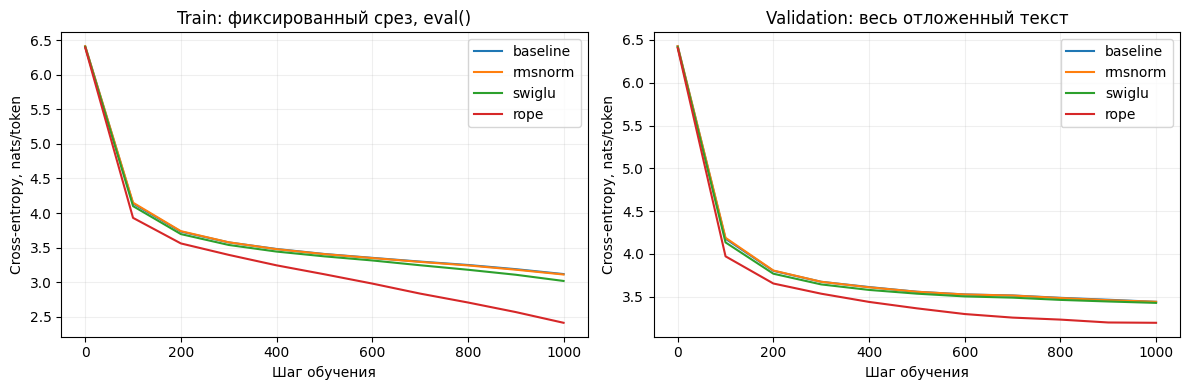

In [27]:
print(f"{'model':10} {'params':>10} {'step':>6} {'train CE':>10} {'val CE':>10} {'PPL':>10} {'train sec':>10}")
for row in summaries:
    print(
        f"{row['name']:10} {row['parameters']:10,d} {row['best_step']:6d} "
        f"{row['train_loss']:10.3f} {row['val_loss']:10.3f} {row['ppl']:10.2f} {row['train_seconds']:10.1f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    for axis, metric in zip(axes, ('train_loss', 'val_loss')):
        axis.plot([r['step'] for r in history], [r[metric] for r in history], label=name)

for axis, title in zip(axes, ('Train: фиксированный срез, eval()', 'Validation: весь отложенный текст')):
    axis.set(xlabel='Шаг обучения', ylabel='Cross-entropy, nats/token', title=title)
    axis.legend()
    axis.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(ARTIFACTS / 'loss_curves.png', dpi=150)
plt.show()


In [28]:
PROMPTS = ['Мой дядя самых честных правил,\n', 'Любви все возрасты покорны;\n']
samples = []
for name, _ in experiments:
    model, saved_merges, saved_vocab, checkpoint = load_checkpoint(ARTIFACTS / f'{name}.pt')
    for prompt in PROMPTS:
        for temperature in (0.0, 0.8):
            torch.manual_seed(SEED)

            prefix = torch.tensor([encode(prompt, saved_merges)], dtype=torch.long, device=DEVICE)
            generated = generate(model, prefix, max_new_tokens=80, temperature=temperature)[0].tolist()
            text = decode(generated, saved_vocab)

            print(f'\n[{name}, step={checkpoint["step"]}, T={temperature}]\n{text}')
            samples.append(
                dict(
                    model=name,
                    step=checkpoint['step'],
                    prompt=prompt,
                    temperature=temperature,
                    text=text,
                )
            )


[baseline, step=1000, T=0.0]
Мой дядя самых честных правил,
И в так, в так в темя в теменный,
И в так, в темя в темя видет,
И в темя в темя время время,
И в темя в темя видит,
И в темя в темя в

[baseline, step=1000, T=0.8]
Мой дядя самых честных правил,
И чуда послю тоховий,
Предниваженье верут;бор,
Проставый горастал оды;
Ни гру но призница, скольною подражда,
Хоть, вослушишь ох 

[baseline, step=1000, T=0.0]
Любви все возрасты покорны;
Она в теменным сней,
Походит сменной доле
И встременным спит, и встременный
И воздетременным спит,
И встременно, воздется встью
И

[baseline, step=1000, T=0.8]
Любви все возрасты покорны;
Но чуда, кним тояли задит;
Мостит одкаю сборыская.
Мне нимал одывоне счит но;
Она нашь, как вечно.
Младое трудется состьем
Поднет

[rmsnorm, step=1000, T=0.0]
Мой дядя самых честных правил,
И в так, что же в тем,
И в тем, в тем, в темя в темя,
И в темя в темя время время,
И в темя в темя в темя в темя,
И в темя в темя в

[rmsnorm, step=1000, T=0.8]
Мой дядя самых че

In [29]:
(ARTIFACTS / 'samples.json').write_text(json.dumps(samples, ensure_ascii=False, indent=2), encoding='utf-8')

4874

### 5.3. Итоговый анализ — TODO 9

Ответьте на вопросы, ссылаясь на вашу таблицу, графики и примеры.

1. Какая конфигурация дала минимальный validation loss? Каков разрыв с baseline и как изменилось число параметров? Укажите устройство, режим и фактический бюджет.
2. Что изменилось при **каждом** последовательном переходе? Объясните хотя бы один результат, который не совпал с вашим ожиданием; если все совпали, укажите альтернативное объяснение.
3. Есть ли признаки переобучения? Почему выбор лучшего checkpoint не превращает validation в независимый test? Что ограничивает выводы при одном seed?
4. Чем отличаются greedy и sampling в ваших примерах? Отделите повторение цитат и стилистическое сходство от способности обобщать. Приведите неудачное продолжение.
5. Почему нельзя по этим прогонам заключить, что RoPE улучшает длинный контекст, а RMSNorm обязательно ускоряет любую LLM? Какой **один** следующий эксперимент помог бы проверить ваше объяснение, и что вы в нём зафиксируете?
6. Назовите одну найденную ошибку и проверку, которая помогла её локализовать. Если ошибок не встретилось, объясните, какую из проверок вы считаете наиболее полезной и почему.

**Основной прогон** (QUICK_RUN=False, GPU T4, 1000 шагов, d_model=192, n_layers=4, n_heads=6, max_seq_len=128, BATCH_SIZE=32, dropout=0.1, lr=3e-4, weight_decay=0.1) выполнен без уменьшения бюджета.

1. Лучший validation loss у rope (RMSNorm + SwiGLU + RoPE) = 3.196. rope vs baseline: val CE лучше на 3.441 - 3.196 = 0.245 nats/token, PPL ниже на 22% (24.44 vs 31.22). Число параметров у baseline 1 969 536, у всех остальных 1 967 808. Разница ровно 9·d = 1728 (это удаление β из 9 норм (2·4+1 = 9)). Доли процента (около 0.09%), как и было предсказано. rope учится дольше всех (37.9с против 29.8с у baseline), т.к RoPE добавляет операции поворота на каждом слое.
2. При переходе с baseline на rmsnorm val CE практически не изменился (3.441), а train CE 3.117 → 3.110, т.е. разница в пределах шума, а число параметров уменьшилось ровно на 1728. Все совпало с ожиданиями. Небольшой выигрыш дал переход на SwiGLU после rmsnorm (снижение всех метрик). Более гибкая нелинейность вместо жёсткого обнуления у ReLU начинает окупаться к 1000 шагам. Самый большой скачок дал переход на rope: Loss на валидации упал существенно, PPL снизился примерно на пятую часть, и train loss тоже резко пошёл вниз. Я ожидала, что RoPE даст маленький эффект: при max_seq_len=128 модель никогда не выходит за длину, на которой обучалась, а именно на длинных последовательностях RoPE должен был бы показывать преимущество перед синусоидами. Получилось наоборот, RoPE дал самый большой выигрыш из всех трёх замен, и на коротком контексте тоже. Скорее всего это связано с тем, что RoPE встраивает относительность в скалярное произведение Q·K и модели не нужно выучивать M_k, как для синусоид. На малом корпусе и коротком обучении это даёт выигрыш даже на коротких последовательностях: синусоидам не хватает данных, чтобы выучить относительность, а RoPE работает «из коробки». Дополнительно RoPE может улучшать обусловленность оптимизации (вращение сохраняет норму, скалярные произведения гладкие по позиции).
3. Судя по разрыву между train  и val признаки переобучения есть, т.к. он увеличивается от baseline к rope (0.324 -> 0.785) сильнее, чем растет val ce. Выбор лучшего checkpoint не превращает validation в независимый test, потому что val участвует в принятии решения: мы фактически подбираем номер шага так, чтобы на val было лучше. Чтобы честно оценить модель, нужен третий набор текста, который не использовался ни при обучении, ни при выборе шага. Все четыре модели обучались с одним и тем же seed и в одном и том же порядке батчей. Это значит, что мы проверили одну конкретную «случайную судьбу» обучения, а не все возможные. Если запустить с другим seed, числа немножко сдвинутся, из-за другой инициализации и другого порядка данных.
4. Greedy (T=0) склонен к зацикливанию.  На baseline и rmsnorm после промпта «Мой дядя самых честных правил,» модель выдаёт одно и то же: «И в так, в так в темя в теменный, / И в так, в темя в темя видет, / И в темя в темя время время…». У swiglu то же самое, но с другим повтором: «И воздруг душе душе душе…». У rope петля выражена слабее и есть связная структура («и вот…», «и вдруг…»). Sampling (T=0.8) из петли выходит, но ценой связности. У baseline/rmsnorm появляются обрывки, похожие на стихи по ритму и словам. Модель выучила форму строки и частотные слова, но не их сочетаемость. У rope и в sampling-режиме появляются осмысленные фрагменты и даже структурные маркеры: «XIV», «XLI». Обобщения языка нет ни у одной модели (недостаточное количсетво теконов и шагов). Когда rope выдаёт «XIV / Но вот снеговье время, вдругом…» - это не обобщение языка, а выучивание паттерна разметки: римская цифра стоит отдельной строкой перед строфой. Это уже не простое запоминание одной строки, но всё ещё не «понимание», модель воспроизводит частотный шаблон. Стилистическое сходство (короткие строки, ритм, окончания на «-ой/-ый/-а») есть у всех моделей, но у rope оно подкреплено связностью, а у остальных только формой.
5. Предполагая «RoPE лучше для длинного контекста», мы имеем в виду, что RoPE кодирует относительные позиции, и поэтому правило «между этими токенами k шагов» переносится на последовательности любой длины, в том числе длиннее, чем те, на которых модель обучалась. То есть предполагаемый выигрыш RoPE должен проявляться именно там, где модель выходит за пределы обученной длины и вынуждена экстраполировать. Наша модель никогда не ставится в ситуацию экстраполяции, а значит, у механизма RoPE, просто нет возможности себя проявить. Мы сравниваем синусоиды и RoPE только на тех длинах, где обе схемы работают «в зоне комфорта», и по этому сравнению нельзя судить, что произойдёт на длине 256, 512 или 1024. RMSNorm не обязательно ускоряет любую LLM во время обучения (мы замеряли только время обучения), и ускорение скорее всего идет на инференсе и дает выигрыш на очень больших моедлях, где каждая операция на каждом слое складывается в заметную экономию. Для проверки можно использовтаь 2×2 факторный эксперимент: обучаем четыре модели на коротких окнах (train max_seq_len=64) при равных данных, seed и бюджете: A (LayerNorm + синусоиды), B (LayerNorm + RoPE), C (RMSNorm + синусоиды), D (RMSNorm + RoPE) так, чтобы A vs B изолировали RoPE, а A vs C изолировали RMSNorm, взаимодействие RoPE×RMSNorm будет видно по (D−C) vs (B−A) Валидируем каждую на длинах 64 / 128 / 256 и меряем PPL (проверка экстраполяции RoPE), а также время инференса (генерация 64 токенов) и пиковую память на A vs C (проверка ускорения RMSNorm). Меняем только norm_type и pos_type, всё остальное фиксируем.
6. При объединении голов в CausalSelfAttention.forward я сначала написала y = y.transpose(1, 2).view(B, T, C). Логика вроде правильная: y имеет форму (B, H, T, D), transpose(1, 2) даёт (B, T, H, D), и дальше view(B, T, C) должен схлопнуть (H, D) в C. Но transpose не копирует данные, а только меняет strides — тензор становится non-contiguous. А view требует contiguous-память и падает с RuntimeError. Ошибка коварная, т.к. дело не в логике, а в layout памяти, и её не видно, если смотреть только на формы. Проверка, которая локализовала. check_baseline(): torch.testing.assert_close(attention(x), attention.out_proj(expected), atol=2e-5, rtol=2e-5). Исправилось .contiguous() перед view. check_baseline() сравнивает мою реализацию с эталонной, то есть ловит не только «код запускается», но и «код считает то же самое». Без неё ошибка всплыла бы позже, в train_step или в check_training, уже как «loss не падает» и диагностика была бы гораздо дольше.